> **Executed copy.** This is `notebooks/colab_run_all.ipynb` as it was run on a free Colab T4 on
> 2026-10-15 (code at `main` 90f6ba9), with every cell's output: the logs, QA report, budget, results
> tables and plots. The raw files these cells wrote are in this folder (`results/t4_run/`); see its README.
>
> What differs from the notebook in the repo today:
> - **Setup.** The Drive mount in the first setup cell timed out. The cell after the HF-token cell ("`DRIVE_ROOT =
>   "/content/vocabx_store"`") was added in Colab and is the one that ran, so all artifacts were on the VM disk.
> - **`prepare`** wrote its artifact and then hung; it was interrupted by hand (fixed since in PR #2).
> - **§7** ran only the bytes-matched Exp2, with BPB-only evaluation; that is now the default cell.
> - **Export.** The `files.download` cell near the end downloaded the results zip.
>
> Cleaned for publishing: Colab account metadata was removed; the first setup cell's output (an accidental,
> interrupted re-run after the study) was cleared; two lines changed by stray typing after the run were
> restored to what ran; the download helper's output and an empty cell were dropped. Nothing else was
> changed.

# Vocabulary expansion on SmolLM2-135M → Greek (Colab driver)

Runs the whole study on a **free Colab T4**: data preparation → tokenizer extension + QA →
throughput calibration → baseline / Exp1 / Exp2 with **matched tokens and steps** → evaluation
→ results table and plots. Everything is cached on Google Drive and every run is resumable,
so a disconnected session continues where it stopped.

| stage | time on a T4 (approx.) |
|---|---|
| data prep (stream ~230 MB, clean, dedup, split) | 10–20 min, once |
| continued-BPE tokenizer (60 MB) + QA | ~3 min, once |
| baseline eval | ~7 min |
| Exp1 / Exp2 training (each) | ≤ 30 min + dev evals |
| final eval per run | ~7 min (Exp2 also evaluates its step-0 state) |

Runtime → Change runtime type → **T4 GPU**.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Code + persistent storage
Either clone the repository (set `REPO_URL`) or upload the repo folder to Drive as `MyDrive/vocabx/repo`.
Artifacts (data, tokenizers, checkpoints, results) go to `MyDrive/vocabx/artifacts`.

In [ ]:
REPO_URL = "https://github.com/nevasini1/smollm2-greek-vocab-expansion.git"   # set to "" to use a copy uploaded to Drive instead
DRIVE_ROOT = "/content/drive/MyDrive/vocabx"

from google.colab import drive
drive.mount("/content/drive")
import os
os.makedirs(DRIVE_ROOT, exist_ok=True)
%cd /content
if REPO_URL:   # (re)clone; leaving the folder first keeps re-runs of this cell safe
    !rm -rf /content/vocabx && git clone -q {REPO_URL} /content/vocabx
else:
    !rm -rf /content/vocabx && cp -r {DRIVE_ROOT}/repo /content/vocabx
%cd /content/vocabx
!pip install -q -e .
WORK = f"{DRIVE_ROOT}/artifacts"
W = f"--set workdir={WORK}"
print("artifacts ->", WORK)

In [ ]:
# Optional: a Hugging Face token raises Hub rate limits (all default datasets are ungated).
# from google.colab import userdata; os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

In [3]:
import os
REPO_URL = "https://github.com/nevasini1/smollm2-greek-vocab-expansion.git"
DRIVE_ROOT = "/content/vocabx_store"
os.makedirs(DRIVE_ROOT, exist_ok=True)
%cd /content
!rm -rf /content/vocabx && git clone -q {REPO_URL} /content/vocabx
%cd /content/vocabx
!pip install -q -e .
WORK = f"{DRIVE_ROOT}/artifacts"
W = f"--set workdir={WORK}"
print("artifacts ->", WORK)

/content
/content/vocabx
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for vocabx (pyproject.toml) ... done
artifacts -> /content/vocabx_store/artifacts


## 2. Data: training pools + fixed, decontaminated eval sets
Greek: Wikipedia (el) + FineWeb-2 ell_Grek (75 MB each) for training; held-out Wikipedia docs, the
official FineWeb-2 test split and Belebele/FLORES passages for evaluation. English: FineWeb-Edu
(SmolLM2's own distribution; also the replay pool), BBC News Jan–Jun 2025 (after SmolLM2's release)
and the parallel Belebele passages. Held-out docs are drawn first; training docs that share a
paragraph or are MinHash near-duplicates of any held-out doc are dropped.

In [4]:
!python -m vocabx prepare --config configs/exp2_extend.yaml {W}

12:52:54 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
tokenizer.json: 100% 2.10M/2.10M [00:00<00:00, 73.3MB/s]
12:52:55 INFO numexpr.utils | NumExpr defaulting to 2 threads.
12:52:55 INFO datasets | TensorFlow version 2.21.0 available.
12:52:55 INFO datasets | JAX version 0.11.1 available.
12:52:56 INFO vocabx | streaming wikimedia/wikipedia [20231101.el] split=train
README.md: 100% 131k/131k [00:00<00:00, 184MB/s]
12:53:09 INFO vocabx | streaming HuggingFaceFW/fineweb-2 [ell_Grek] split=test
README.md: 100% 329k/329k [00:00<00:00, 114MB/s]
Resolving data files: 100% 20/20 [00:00<00:00, 12104.77it/s]
12:53:17 INFO vocabx | streaming HuggingFaceFW/fineweb-2 [ell_Grek] split=train
Resolving data files: 100% 20/20 [00:00<00:00, 21421.37it/s]
README.md: 100% 25.5k/25.5k [00:00<00:00, 63.1MB/s]
ell_Grek.jsonl: 100% 3.88M/3.88M [00:00<00:00, 299MB/s]
Generating t

## 3. Extend the tokenizer (continued BPE, +8,000 Greek tokens) and run the QA harness
Checks: original ids/merges untouched · English and any non-Greek text tokenize identically ·
`decode(encode(x)) == x` · every new token reachable (self-tokenization test) · compression and
vocab-size curve (1k…16k from merge prefixes).

In [5]:
!python -m vocabx tokenizer --config configs/exp2_extend.yaml {W} | head -80

13:00:18 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
13:00:19 INFO vocabx | data artifact exists: /content/vocabx_store/artifacts/data/1f6728b731df
13:00:19 INFO vocabx | building tokenizer: extender=continued_bpe, 8000 new tokens, 60 MB of Greek training text
13:00:44 INFO vocabx | continued BPE: 300241 Greek word types (4713444 occurrences) after base segmentation
13:01:07 INFO vocabx |   1000 merges (last: 'Î´Ïİ', freq 2396)
13:01:11 INFO vocabx |   2000 merges (last: 'Î¼Î±ÏĦÎ¹ÎºÎ®', freq 1124)
13:01:15 INFO vocabx |   3000 merges (last: 'ĠÏĮÏģÎ¿ÏĤ', freq 688)
13:01:17 INFO vocabx |   4000 merges (last: 'Î±Î½ÏĦÎ±', freq 479)
13:01:19 INFO vocabx |   5000 merges (last: 'ÏĥÎºÎµÏĪÎ·', freq 364)
13:01:20 INFO vocabx |   6000 merges (last: 'ĠÎ²ÏģÎ±Î²ÎµÎ¯Î¿', freq 288)
13:01:21 INFO vocabx |   7000 merges (last: 'ĠÎ¡Îµ', freq 236)
13:01:23 INFO vocabx |   800

## 4. Fix the matched step budget ONCE (calibrated on the slower arm, Exp2)
`calibrate` measures throughput on this GPU and writes `artifacts/budget.json` with
`max_steps = min(steps that fit 27 min, steps the Greek pool covers without repetition)`.
Every later run, in this and any future session, reads that file, so a reconnect can never
change the budget between arms. Delete `budget.json` (or pass `--force`) only to start over.

In [6]:
!python -m vocabx calibrate --config configs/exp2_extend.yaml {W} --steps 20 --minutes 27
import json
budget = json.load(open(f"{WORK}/budget.json"))
cal = budget["from_calibration"]
print({k: cal[k] for k in ["tokens_per_second", "suggested_max_steps", "pool_cap_steps", "recommended_max_steps",
                           "peak_memory_gb", "greek_MB_available", "sdpa"]})
print("matched budget: max_steps =", budget["max_steps"], f"({budget['max_steps'] * cal['tokens_per_step'] / 1e6:.1f}M tokens per arm)")

13:03:10 INFO vocabx | data artifact exists: /content/vocabx_store/artifacts/data/1f6728b731df
13:03:14 INFO vocabx | attention: disabled (repeat_kv; pre-Ampere GPU)
13:03:20 INFO numexpr.utils | NumExpr defaulting to 2 threads.
13:03:21 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
config.json: 100% 704/704 [00:00<00:00, 2.56MB/s]

model.safetensors: downloading bytes:  54% 146M/269M [00:01<00:00, 178MB/s, 12.4MB/s  ]
model.safetensors: reconstructing file:  45% 120M/269M [00:01<00:01, 90.8MB/s]
model.safetensors: downloading bytes:  65% 174M/269M [00:01<00:00, 162MB/s, 14.9MB/s  ]
model.safetensors: downloading bytes:  74% 198M/269M [00:01<00:00, 147MB/s, 17.7MB/s  ]
model.safetensors: downloading bytes:  87% 233M/269M [00:01<00:00, 156MB/s, 19.7MB/s  ]
model.safetensors: downloading bytes: 100% 233M/233M [00:01<00:00, 125MB/s, 21.2MB/s  ]
model.safetensor

## 5. (Optional) LR probe on dev data, both arms, 150 steps each (~1 h total)
Pre-registered rule: the largest LR whose English-dev loss is ≤ 1/3 of its Greek-dev gain, both
measured from the ORIGINAL model and averaged over arms. The choice is written to
`artifacts/lr_choice.json`, and all later trained runs pick it up automatically. Run it before §6.

In [ ]:
RUN_PROBE = False
if RUN_PROBE:
    # curves only runs if the probe plan succeeded, and refuses to decide on incomplete runs
    !python -m vocabx plan configs/plans/lr_probe.yaml {W} && python -m vocabx curves --workdir {WORK} --runs probe_exp1_lr1e-4 probe_exp2_lr1e-4 probe_exp1_lr3e-4 probe_exp2_lr3e-4 probe_exp1_lr1e-3 probe_exp2_lr1e-3

## 6. Main comparison: baseline, Exp1, Exp2 (matched tokens and steps)
Resumable: if Colab disconnects, re-run this cell; finished runs are skipped and the
interrupted one resumes from its last checkpoint.

In [7]:
!python -m vocabx plan configs/plans/main.yaml {W}

13:06:37 INFO vocabx | === plan: base (/content/vocabx/configs/plans/../base_model.yaml)
13:06:38 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
13:06:38 INFO vocabx | tokenizer bundle saved to /content/vocabx_store/artifacts/tokenizers/base-5ae0947d45a5 (vocab 49152 = 49152 + 0)
13:06:38 INFO vocabx | data artifact exists: /content/vocabx_store/artifacts/data/1f6728b731df
13:06:41 INFO vocabx | attention: disabled (repeat_kv; pre-Ampere GPU)
13:06:43 INFO numexpr.utils | NumExpr defaulting to 2 threads.
Loading weights: 100% 272/272 [00:00<00:00, 1157.34it/s]
13:08:30 INFO vocabx | [final] wikipedia_el           BPB 1.2997  tok/word 5.67  mass_new 0.0000
13:08:30 INFO vocabx | [final] fineweb2_el            BPB 1.2820  tok/word 5.48  mass_new 0.0000
13:08:30 INFO vocabx | [final] belebele_el            BPB 1.2735  tok/word 5.51  mass_new 0.0000
13:08:30 INFO

# SmolLM2-135M -> Greek: fine-tune (Exp1) vs. vocabulary extension (Exp2)

Baseline: `base`; reference for extra-cost columns: `exp1_finetune`. 95% CIs from a paired bootstrap over documents (10000 resamples). BPB = bits per UTF-8 byte (lower is better).

Token/step budgets and optimisation (peak LR, schedule, seq len) matched across trained runs: **yes** {'exp1_finetune': (14843904, 453), 'exp2_extend': (14843904, 453)}

| model | vocab | steps | tokens (M) | Greek MB seen | Greek epochs | train PFLOPs | train min | EL BPB | ΔEL vs base | EN BPB | ΔEN vs base | extra EN cost vs ref | extra EL gain vs ref | EN-per-EL exchange |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| `base` | 49152 | 0 | 0.0 | 0.0 | 0.00 | 0.00 | 0.0 | 1.2851 [1.2790, 1.2914] | +0.0000 [+0.0000, +0.0000] | 0.9643 [0.9568, 0.9720] | +0.0000 [+0.0000, +0.0000] | -0.1524 [-0.1539, -0.1509] | -0.4115 [-0.4154, -0.4078] | n/a: worse EL, better EN |
| `exp1_finetune` | 49152 | 453 | 14.8 | 31.8 | 0.21 | 13.55 | 28.1 | 0.8736 [0.8680, 0.8794] | -0.4115 [-0.4154, -0.4078] | 1.1167 [1.1085, 1.1249] | +0.1524 [+0.1509, +0.1539] | - | - | - |
| `exp2_extend` | 57152 | 453 | 14.8 | 90.5 | 0.60 | 13.96 | 29.0 | 0.7512 [0.7449, 0.7575] | -0.5339 [-0.5388, -0.5291] | 1.2012 [1.1928, 1.2098] | +0.2369 [+0.2346, +0.2392] | +0.0845 [+0.0827, +0.0863] | +0.1224 [+0.1206, +0.1242] | 0.690 [0.672, 0.709] |
| `exp2_extend@step0` | 57152 | 0 | 0.0 | 0.0 | 0.00 | 0.00 | 0.0 | 2.0337 [2.0239, 2.0437] | +0.7486 [+0.7420, +0.7554] | 0.9646 [0.9570, 0.9722] | +0.0002 [+0.0002, +0.0003] | -0.1522 [-0.1536, -0.1507] | -1.1601 [-1.1663, -1.1539] | n/a: worse EL, better EN |

## Per eval set (BPB, point estimates)

| model | wikipedia_el | fineweb2_el | belebele_el | fineweb_edu_en | bbc_news_2025_en | belebele_en |
|---|---|---|---|---|---|---|
| `base` | 1.2997 | 1.2820 | 1.2735 | 0.9178 | 1.0486 | 0.9266 |
| `exp1_finetune` | 0.8618 | 0.9081 | 0.8508 | 1.0595 | 1.2049 | 1.0857 |
| `exp2_extend` | 0.7328 | 0.7945 | 0.7262 | 1.1308 | 1.2945 | 1.1783 |
| `exp2_extend@step0` | 2.0993 | 2.0533 | 1.9485 | 0.9181 | 1.0488 | 0.9268 |

## English probability mass on new (Greek) tokens

`mass_new` = mean probability the model assigns to the new token ids at English positions; `BPB (old-vocab renorm)` removes that leakage, isolating representational forgetting.

| model | set | BPB | BPB (old-vocab renorm) | mass_new |
|---|---|---|---|---|
| `exp2_extend` | fineweb_edu_en | 1.1308 | 1.1091 | 0.05369 |
| `exp2_extend` | bbc_news_2025_en | 1.2945 | 1.2662 | 0.06490 |
| `exp2_extend` | belebele_en | 1.1783 | 1.1475 | 0.07420 |
| `exp2_extend@step0` | fineweb_edu_en | 0.9181 | 0.9178 | 0.00074 |
| `exp2_extend@step0` | bbc_news_2025_en | 1.0488 | 1.0486 | 0.00056 |
| `exp2_extend@step0` | belebele_en | 0.9268 | 0.9266 | 0.00081 |

## Tokenizer efficiency on held-out text

| model | set | tokens/word | bytes/token |
|---|---|---|---|
| `base` | wikipedia_el | 5.67 | 2.12 |
| `base` | fineweb2_el | 5.48 | 2.16 |
| `base` | belebele_el | 5.51 | 2.19 |
| `base` | fineweb_edu_en | 1.32 | 4.64 |
| `base` | bbc_news_2025_en | 1.31 | 4.48 |
| `base` | belebele_en | 1.27 | 4.79 |
| `exp1_finetune` | wikipedia_el | 5.67 | 2.12 |
| `exp1_finetune` | fineweb2_el | 5.48 | 2.16 |
| `exp1_finetune` | belebele_el | 5.51 | 2.19 |
| `exp1_finetune` | fineweb_edu_en | 1.32 | 4.64 |
| `exp1_finetune` | bbc_news_2025_en | 1.31 | 4.48 |
| `exp1_finetune` | belebele_en | 1.27 | 4.79 |
| `exp2_extend` | wikipedia_el | 2.05 | 5.87 |
| `exp2_extend` | fineweb2_el | 1.85 | 6.42 |
| `exp2_extend` | belebele_el | 1.74 | 6.92 |
| `exp2_extend` | fineweb_edu_en | 1.32 | 4.64 |
| `exp2_extend` | bbc_news_2025_en | 1.31 | 4.48 |
| `exp2_extend` | belebele_en | 1.27 | 4.79 |

## Zero-shot cloze tasks (acc_norm, 95% CI; gold-answer BPB)

| model | arc_easy_el | arc_easy_en | hellaswag_el | hellaswag_en | piqa_en |
|---|---|---|---|---|---|
| `base` | 0.254 [0.218,0.292] / 1.654 | 0.558 [0.516,0.602] / 1.157 | 0.293 [0.255,0.331] / 1.174 | 0.409 [0.367,0.453] / 0.899 | 0.674 [0.632,0.714] / 1.182 |
| `exp1_finetune` | 0.240 [0.202,0.276] / 1.257 | 0.520 [0.476,0.562] / 1.265 | 0.323 [0.285,0.361] / 0.846 | 0.403 [0.361,0.445] / 1.035 | 0.652 [0.612,0.694] / 1.336 |
| `exp2_extend` | 0.268 [0.230,0.306] / 1.210 | 0.484 [0.442,0.528] / 1.483 | 0.287 [0.246,0.329] / 0.732 | 0.381 [0.339,0.425] / 1.100 | 0.638 [0.598,0.680] / 1.437 |

## Greedy generation probes (byte-budgeted)

| model | lang | script ratio | distinct-2 | repeated 4-grams | bytes/token |
|---|---|---|---|---|---|
| `base` | el | 1.000 | 0.330 | 0.616 | 1.96 |
| `base` | en | 1.000 | 0.531 | 0.380 | 4.32 |
| `exp1_finetune` | el | 1.000 | 0.554 | 0.378 | 2.00 |
| `exp1_finetune` | en | 0.605 | 0.579 | 0.324 | 3.17 |
| `exp2_extend` | el | 1.000 | 0.799 | 0.113 | 5.83 |
| `exp2_extend` | en | 0.407 | 0.602 | 0.292 | 5.32 |

## Budget and exposure

- `exp1_finetune`: 453 steps, 14.8M tokens, Greek bytes 31.8MB, English bytes 0.0MB, 13.55 PFLOPs, 28.1 min, GradScaler skipped 0 steps, new-token exposure {}
- `exp2_extend`: 453 steps, 14.8M tokens, Greek bytes 90.5MB, English bytes 0.0MB, 13.96 PFLOPs, 29.0 min, GradScaler skipped 0 steps, new-token exposure {'median': 538.0, 'p10': 265.0, 'min': 0, 'never_seen': 3, 'seen_lt_10': 24, 'seen_lt_100': 251}


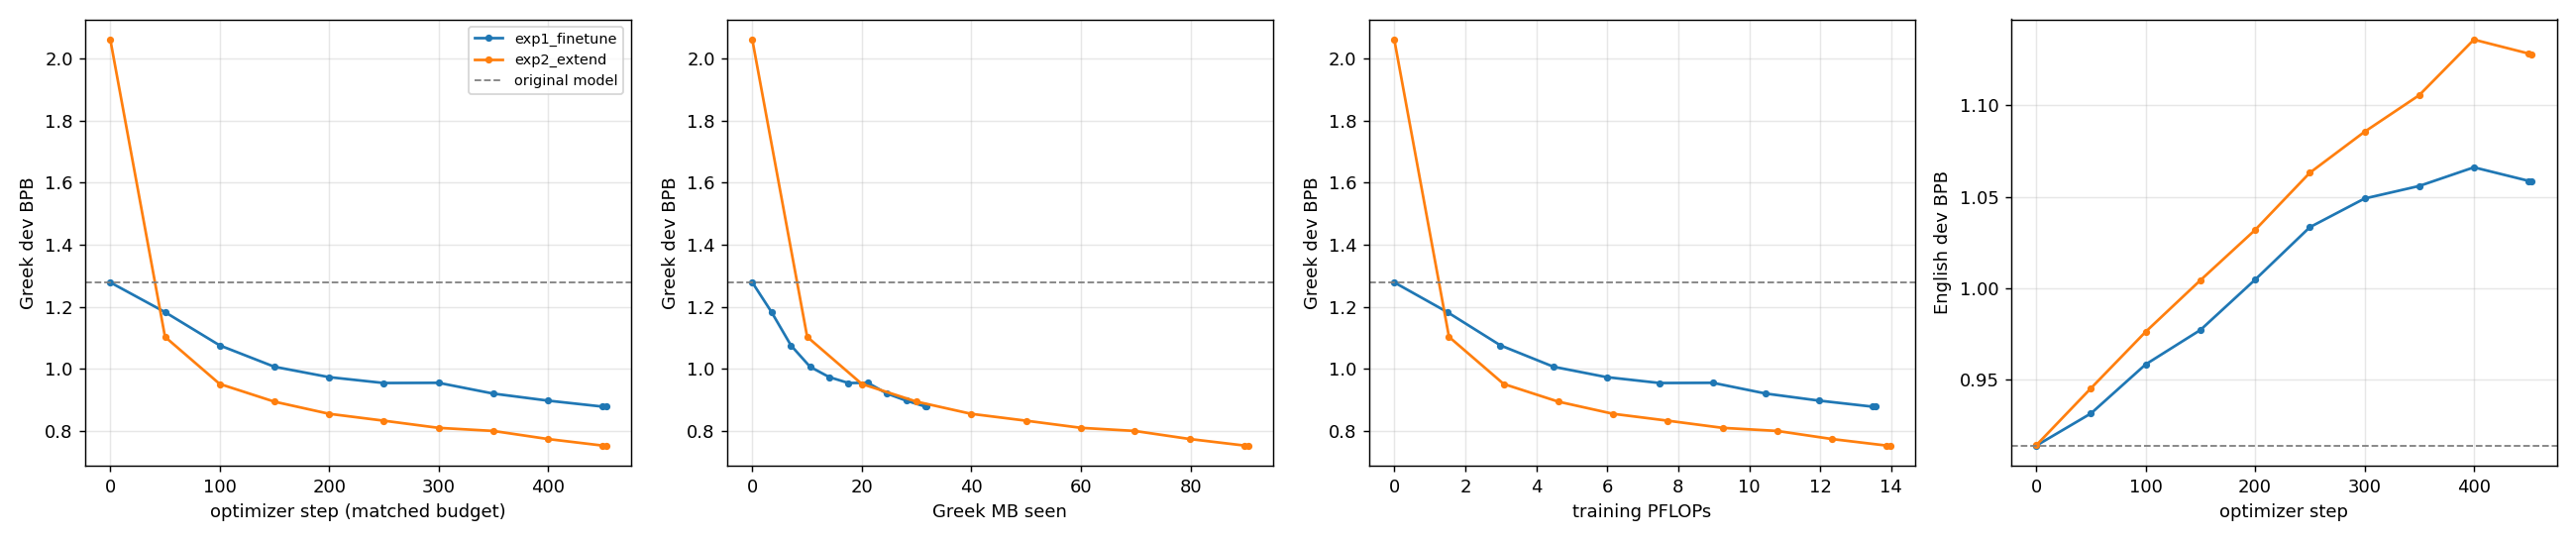

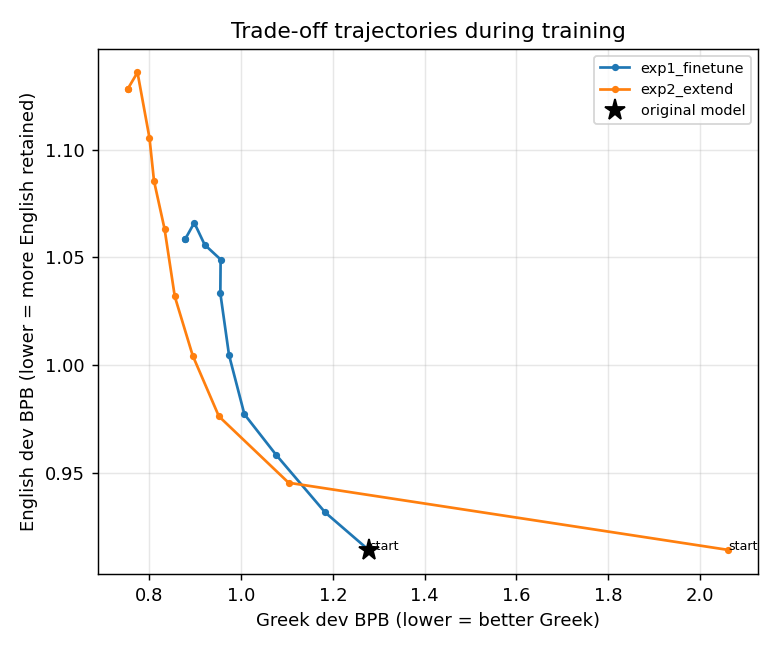

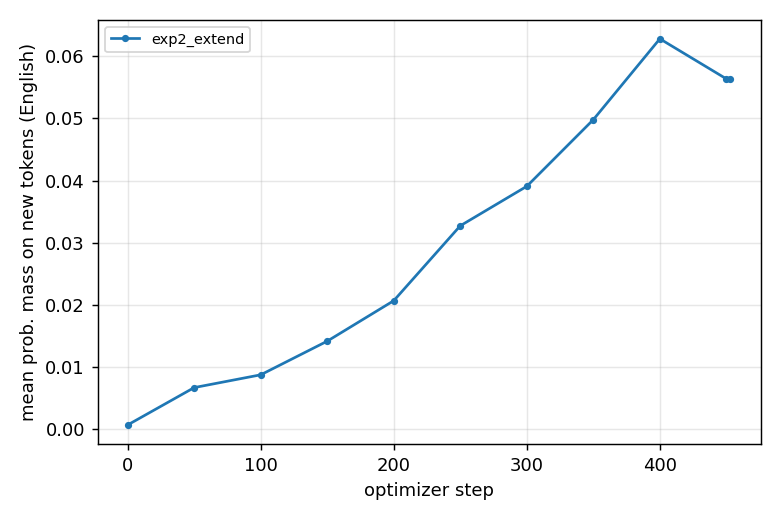

In [8]:
from IPython.display import Markdown, Image, display
R = f"{WORK}/results/main"
display(Markdown(open(f"{R}/results.md").read()))
for img in ["learning_curves.png", "tradeoff_trajectories.png", "english_mass_on_new_tokens.png"]:
    if os.path.exists(f"{R}/{img}"):
        display(Image(f"{R}/{img}"))

## 6b. (Optional) Weight-interpolation frontiers (eval only, ~10 min per run on dev sets)
θ(α) = (1−α)·θ_start + α·θ_final for each arm. θ_start is the expanded step-0 model for Exp2. Comparing frontiers shows English given up per unit of Greek gained, independent of where the 30-min run stopped.

14:47:01 INFO vocabx | exp1_finetune: max_steps 600 -> 453 from /content/vocabx_store/artifacts/budget.json
14:47:07 INFO numexpr.utils | NumExpr defaulting to 2 threads.
Loading weights: 100% 272/272 [00:00<00:00, 1140.52it/s]
Loading weights: 100% 272/272 [00:00<00:00, 331.13it/s]
14:47:37 INFO vocabx | [interp exp1_finetune] alpha=0.00  EL 1.2773  EN 0.9051
14:48:02 INFO vocabx | [interp exp1_finetune] alpha=0.25  EL 1.1113  EN 0.9145
14:48:28 INFO vocabx | [interp exp1_finetune] alpha=0.50  EL 0.9861  EN 0.9418
14:48:55 INFO vocabx | [interp exp1_finetune] alpha=0.75  EL 0.9073  EN 0.9867
14:49:22 INFO vocabx | [interp exp1_finetune] alpha=1.00  EL 0.8784  EN 1.0505
14:49:25 INFO vocabx | exp2_extend: max_steps 600 -> 453 from /content/vocabx_store/artifacts/budget.json
14:49:29 INFO numexpr.utils | NumExpr defaulting to 2 threads.
Loading weights: 100% 272/272 [00:00<00:00, 1182.74it/s]
14:49:31 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated request

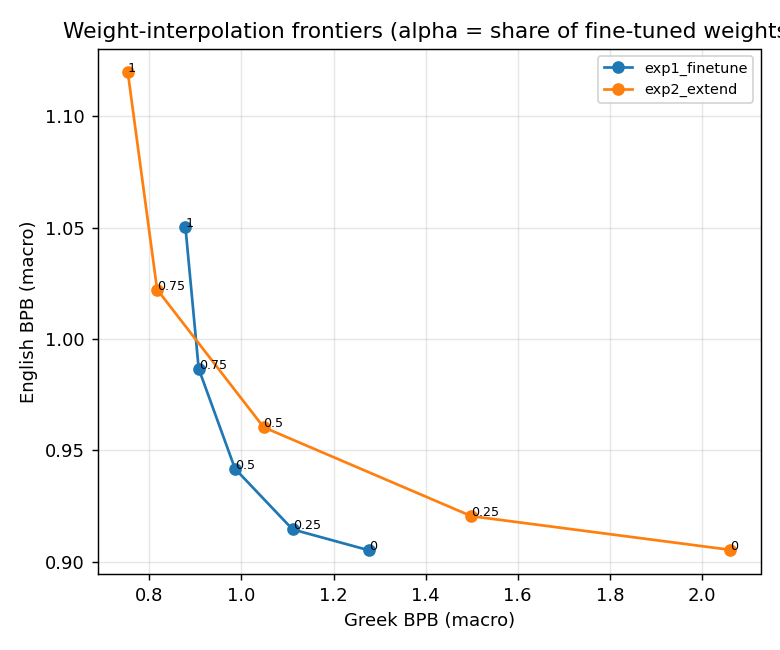

In [9]:
DEV = "wikipedia_el:dev fineweb2_el:dev fineweb_edu_en:dev"
!python -m vocabx interpolate --config configs/exp1_finetune.yaml {W} --sets {DEV}
!python -m vocabx interpolate --config configs/exp2_extend.yaml {W} --sets {DEV} --plot-runs exp1_finetune exp2_extend
display(Image(f"{WORK}/results/interpolation_frontiers.png"))

## 7. Ablations and seeds (optional; each ≈ one more training run)
Run a prefix of the ranked list, e.g. the byte-matched Exp2 and the 20% English-replay pair.

In [11]:
!python -m vocabx plan configs/plans/ablations.yaml {W} --only exp2_bytes_matched --set 'eval.downstream=[]' --set eval.generation=false --set eval.full_eval_at_step0=false --set train.eval_every=100

14:55:24 INFO vocabx | === plan: exp2_bytes_matched (/content/vocabx/configs/plans/../ablations/exp2_bytes_matched.yaml)
14:55:25 INFO vocabx | data artifact exists: /content/vocabx_store/artifacts/data/1f6728b731df
14:55:27 INFO vocabx | attention: disabled (repeat_kv; pre-Ampere GPU)
14:55:29 INFO numexpr.utils | NumExpr defaulting to 2 threads.
Loading weights: 100% 272/272 [00:00<00:00, 1227.33it/s]
14:55:31 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
14:55:32 INFO vocabx | expanded vocab 49152 -> 57152 with fvt_mean (new-row norm 2.57 vs old 3.18)
14:55:33 INFO vocabx | greek_bytes budget: 31822034 reference bytes -> 159 steps
14:55:34 INFO vocabx | run exp2_bytes_matched: 159 steps x 32768 tokens = 5.2M tokens; device=cuda amp=torch.float16; vocab 57152 (+8000)
14:55:34 INFO vocabx | el stream: 5088 blocks needed, 24047 per epoch -> 0.21 epochs
14:55

In [ ]:
# Training-noise estimate (two more seeds per arm, common-random-number pairs):
# !python -m vocabx plan configs/plans/seeds.yaml {W}

In [ ]:
R = f"{WORK}/results/ablations"
if os.path.exists(f"{R}/results.md"):
    display(Markdown(open(f"{R}/results.md").read()))

In [10]:
from google.colab import files
files.download("/content/results_main.zip")